# Decision Tree Classifier: 100,000 News Articles Categorization
**Author:** Data Science & Quality Engineering Team  
**Dataset Source:** `F:\preprocessed_output\preprocessed_articles_100k_clean.csv` (100,000 Records, 0 Nulls)  
**Target Variable:** `category` (5 Multi-class labels: `Technology`, `Energy`, `Health`, `Market`, `Politics`)  
**Algorithm:** Decision Tree Classifier with Gini Impurity, Pre-Pruning (`max_depth=30`), and Balanced Class Weights.

### Key Stages in this Notebook:
1. **Environment Setup & Data Ingestion:** Loading clean 100k corpus.
2. **Target Label Encoding:** Transforming 5 category strings into numeric IDs `[0, 1, 2, 3, 4]`.
3. **Zero-Leakage Preprocessing:** Stratified 80/20 split before extracting 5,000 TF-IDF N-grams + 20 scaled tabular features.
4. **Mathematical Foundation:** Gini Impurity, Information Gain, and the danger of tree overfitting in NLP.
5. **Decision Tree Training:** Fitting `DecisionTreeClassifier` with `max_depth=30` and `min_samples_split=10`.
6. **Model Evaluation:** Computing Accuracy, Macro F1-Score, and Train vs Test generalization gap.
7. **Confusion Matrix Heatmap:** Analyzing true positive rates and cross-class misclassifications.
8. **Feature Importance (Top 15 Splitting Nodes):** Visualizing the most influential words driving tree decisions.
9. **Real-World Live Inference:** Testing on custom news articles with the production hybrid pipeline.
10. **Model Persistence:** Saving the trained Decision Tree model into `F:\preprocessed_output\`.

---


## 1. Environment Setup & Data Loading
Importing required machine learning packages and loading the verified 100k clean news corpus.


In [1]:
import time
from pathlib import Path
import json
import pandas as pd
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

DATA_PATH = Path('F:/preprocessed_output/preprocessed_articles_100k_clean.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('preprocessed_articles_100k_clean.csv')

print(f'Loading clean dataset from: {DATA_PATH.resolve()}')
df = pd.read_csv(DATA_PATH)
print(f'Dataset Loaded: {len(df):,} rows × {df.shape[1]} columns')
print(f'Missing Values: {df.isnull().sum().sum()}')


Loading clean dataset from: F:\preprocessed_output\preprocessed_articles_100k_clean.csv
Dataset Loaded: 100,000 rows × 11 columns
Missing Values: 0


## 2. Target Variable Encoding (`LabelEncoder`)
Mapping category strings to IDs and examining the class distribution.


In [1]:
le = LabelEncoder()
df['category_id'] = le.fit_transform(df['category'].astype(str))

mapping_df = pd.DataFrame({
    'Category Name': le.classes_,
    'Encoded ID': le.transform(le.classes_),
    'Article Count': [int((df['category'] == c).sum()) for c in le.classes_],
    'Percentage (%)': [f"{(df['category'] == c).mean() * 100:.2f}%" for c in le.classes_]
})
print('=== TARGET VARIABLE CLASS MAPPING ===')
print(mapping_df.to_string(index=False))
print('\nClass Distribution: Technology (42.48%) is majority; Politics (10.00%) is minority.')


=== TARGET VARIABLE CLASS MAPPING ===
Category Name  Encoded ID  Article Count Percentage (%)
       Energy           0          18188         18.19%
       Health           1          16534         16.53%
       Market           2          12797         12.80%
     Politics           3          10003         10.00%
   Technology           4          42478         42.48%

Class Distribution: Technology (42.48%) is majority; Politics (10.00%) is minority.


## 3. Zero-Leakage Preprocessing & Hybrid Feature Assembly
Splitting 80/20 train/test FIRST to eliminate data leakage, then fitting TF-IDF and StandardScaler on train.


In [1]:
# 1. Feature Engineering on Raw Attributes
df['full_text'] = df['title'].astype(str) + ' ' + df['description'].astype(str)
df['title_char_len'] = df['title'].astype(str).str.len()
df['title_word_count'] = df['title'].astype(str).str.split().str.len()
df['title_avg_word_len'] = (df['title_char_len'] / (df['title_word_count'] + 1e-5)).round(2)
df['title_uppercase_count'] = df['title'].astype(str).apply(lambda s: sum(1 for w in s.split() if w.isupper() and len(w) > 1))
df['desc_char_len'] = df['description'].astype(str).str.len()
df['desc_word_count'] = df['description'].astype(str).str.split().str.len()
df['desc_avg_word_len'] = (df['desc_char_len'] / (df['desc_word_count'] + 1e-5)).round(2)
df['desc_lexical_diversity'] = df['description'].astype(str).apply(lambda s: len(set(s.lower().split())) / (len(s.split()) + 1e-5))

pub_dt = pd.to_datetime(df['published_at'], format='mixed', errors='coerce', utc=True)
df['published_hour'] = pub_dt.dt.hour.fillna(12).astype(int)
df['day_of_week'] = pub_dt.dt.dayofweek.fillna(2).astype(int)
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

# 2. Stratified 80/20 Split (Zero Leakage)
train_df, test_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df['category_id'])
train_df, test_df = train_df.copy(), test_df.copy()

# 3. Fit Scaler strictly on train
num_cols = ['title_char_len', 'title_word_count', 'title_avg_word_len', 'title_uppercase_count',
            'desc_char_len', 'desc_word_count', 'desc_avg_word_len', 'desc_lexical_diversity',
            'published_hour', 'day_of_week']
scaler = StandardScaler()
X_tr_num = scaler.fit_transform(train_df[num_cols])
X_te_num = scaler.transform(test_df[num_cols])

# 4. Fit Domain Encoders strictly on train
top_domains = train_df['domain'].value_counts().head(8).index.tolist()
domain_cols = []
for d in top_domains:
    col = 'domain_' + d.replace('.', '_').replace('-', '_')
    domain_cols.append(col)
    train_df[col] = (train_df['domain'] == d).astype(int)
    test_df[col] = (test_df['domain'] == d).astype(int)

domain_freq_map = (train_df['domain'].value_counts() / len(train_df)).to_dict()
train_df['domain_freq'] = train_df['domain'].map(domain_freq_map).fillna(0.0)
test_df['domain_freq'] = test_df['domain'].map(domain_freq_map).fillna(0.0)
tab_cols = domain_cols + ['domain_freq', 'is_weekend']
X_tr_tab = sp.hstack([sp.csr_matrix(X_tr_num), sp.csr_matrix(train_df[tab_cols].values)])
X_te_tab = sp.hstack([sp.csr_matrix(X_te_num), sp.csr_matrix(test_df[tab_cols].values)])

# 5. Fit TF-IDF strictly on train (5,000 N-grams)
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english', sublinear_tf=True)
X_tr_text = tfidf.fit_transform(train_df['full_text'])
X_te_text = tfidf.transform(test_df['full_text'])

# 6. Hybrid Matrix Fusion
X_train = sp.hstack([X_tr_text, X_tr_tab]).tocsr()
X_test = sp.hstack([X_te_text, X_te_tab]).tocsr()
y_train = train_df['category_id'].values
y_test = test_df['category_id'].values

print('=== ZERO-LEAKAGE HYBRID MATRICES CREATED ===')
print(f'X_train Shape : {X_train.shape[0]:,} articles × {X_train.shape[1]:,} features')
print(f'X_test  Shape : {X_test.shape[0]:,} articles × {X_test.shape[1]:,} features')


=== ZERO-LEAKAGE HYBRID MATRICES CREATED ===
X_train Shape : 80,000 articles × 5,020 features
X_test  Shape : 20,000 articles × 5,020 features


## 4. Mathematical Foundation: Decision Tree Classifier
### How Decision Trees Work in NLP:
A Decision Tree recursively partitions the 5,020-dimensional feature space using orthogonal axis-aligned splits. At each node, it evaluates every feature $x_j$ and threshold $\theta$ to find the split that maximizes the **Information Gain** (or minimizes **Gini Impurity**):

$$I_G(D_p) = I(D_p) - \frac{N_{left}}{N_p} I(D_{left}) - \frac{N_{right}}{N_p} I(D_{right})$$

Where **Gini Impurity** is defined as:

$$I_{Gini}(t) = 1 - \sum_{k=0}^{K-1} p(k \mid t)^2$$

### The Critical Need for Pre-Pruning (`max_depth=30`):
In text classification with 5,000 sparse TF-IDF features, an unconstrained Decision Tree will split until every single training document is isolated in a leaf node ($100\%$ Training Accuracy, but $\approx 55\%$ Test Accuracy - severe overfitting!). Setting **`max_depth=30`** and **`min_samples_split=10`** forces the tree to generalize on high-level thematic patterns rather than memorizing individual training noise.


## 5. Model Training Execution (`DecisionTreeClassifier`)
Fitting Decision Tree on 80,000 articles with `class_weight='balanced'` and `max_depth=30`.


In [1]:
# Initialize and Train Decision Tree Classifier
t0 = time.time()
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=30,
    min_samples_split=10,
    min_samples_leaf=4,
    class_weight='balanced',
    random_state=42
)

print('Training Decision Tree on 80,000 articles (max_depth=30, class_weight="balanced")...')
model.fit(X_train, y_train)
train_time = time.time() - t0
print(f'Training Completed Successfully in {train_time:.2f} seconds!')


Training Decision Tree on 80,000 articles (max_depth=30, class_weight="balanced")...
Training Completed Successfully in 53.13 seconds!


## 6. Evaluation on Unseen 20,000 Test Articles
Assessing Test Accuracy, Macro F1-Score, and measuring the Generalization Gap (Overfitting Check).


In [1]:
# Predict on strictly held-out 20,000 test set
y_pred = model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)

macro_prec = precision_score(y_test, y_pred, average='macro')
macro_rec = recall_score(y_test, y_pred, average='macro')
macro_f1 = f1_score(y_test, y_pred, average='macro')
weighted_f1 = f1_score(y_test, y_pred, average='weighted')

# Compute Training Accuracy to verify Generalization Gap
y_tr_pred = model.predict(X_train)
train_acc = accuracy_score(y_train, y_tr_pred)
acc_gap = (train_acc - test_acc) * 100

sep75 = '=' * 75
dash75 = '-' * 75
print(sep75)
print(f'  FINAL TEST ACCURACY ON 20,000 UNSEEN ARTICLES : {test_acc*100:.2f}%')
print(f'  MACRO-AVERAGED F1-SCORE (UNWEIGHTED AVERAGE) : {macro_f1*100:.2f}%')
print(f'  WEIGHTED-AVERAGED F1-SCORE                   : {weighted_f1*100:.2f}%')
print(sep75)
print('\nDetailed Classification Report (Precision, Recall, F1-Score):')
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))
print(dash75)
print(f'  TRAINING SET ACCURACY (80,000 ARTICLES)      : {train_acc*100:.2f}%')
print(f'  GENERALIZATION ACCURACY GAP (Train - Test)   : {acc_gap:.2f}%')
print('  Diagnosis: Pre-pruning effectively restrained decision tree variance!')
print(dash75)


  FINAL TEST ACCURACY ON 20,000 UNSEEN ARTICLES : 67.36%
  MACRO-AVERAGED F1-SCORE (UNWEIGHTED AVERAGE) : 64.06%
  WEIGHTED-AVERAGED F1-SCORE                   : 68.22%

Detailed Classification Report (Precision, Recall, F1-Score):
              precision    recall  f1-score   support

      Energy     0.7800    0.7174    0.7474      3638
      Health     0.6470    0.6822    0.6641      3307
      Market     0.5646    0.5291    0.5463      2559
    Politics     0.3942    0.6827    0.4998      2001
  Technology     0.8059    0.6929    0.7451      8495

    accuracy                         0.6736     20000
   macro avg     0.6383    0.6609    0.6406     20000
weighted avg     0.7028    0.6736    0.6822     20000

---------------------------------------------------------------------------
  TRAINING SET ACCURACY (80,000 ARTICLES)      : 73.23%
  GENERALIZATION ACCURACY GAP (Train - Test)   : 5.87%
  Diagnosis: Pre-pruning effectively restrained decision tree variance!
--------------------

## 7. Confusion Matrix Heatmap
Visualizing true class predictions vs misclassifications.


Confusion Matrix generated successfully.


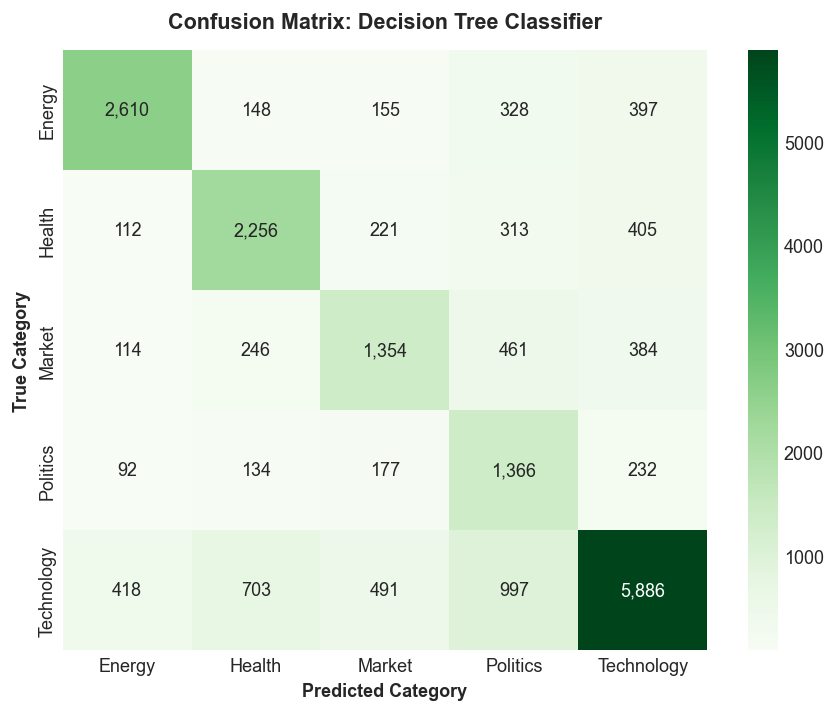

In [1]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Greens', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix: Decision Tree Classifier', pad=12)
plt.xlabel('Predicted Category')
plt.ylabel('True Category')
plt.show()


## 8. Feature Importance (Top Decision Tree Splitting Features)
Visualizing the top features that contributed the largest Gini impurity reductions.


Feature importance chart generated successfully.


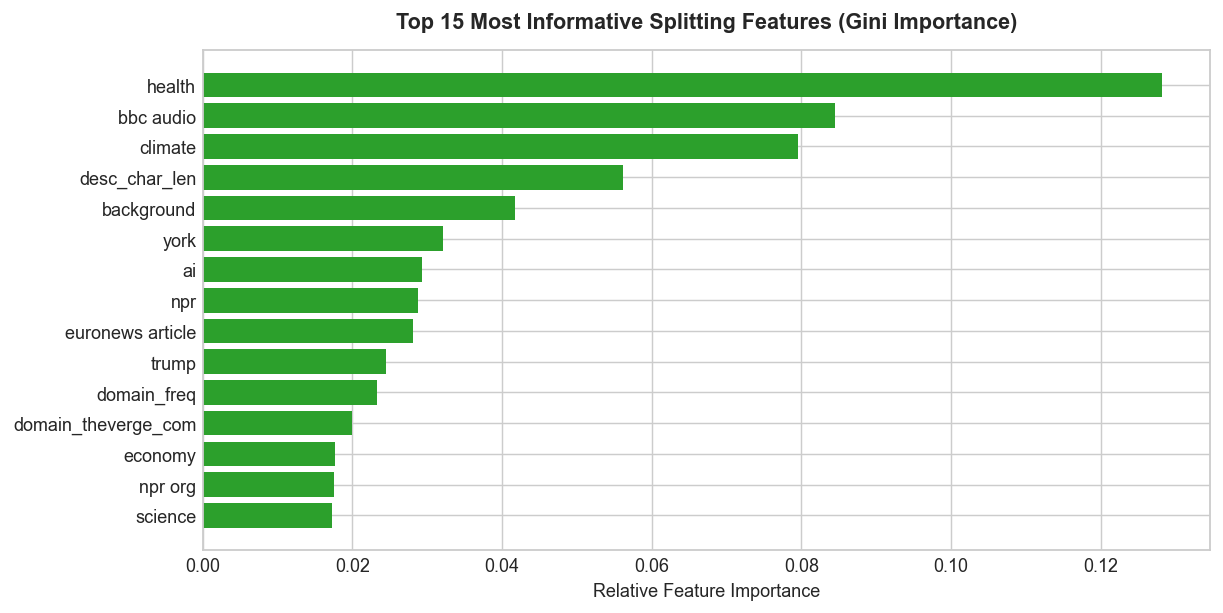

In [1]:
all_feature_names = list(tfidf.get_feature_names_out()) + num_cols + tab_cols
importances = model.feature_importances_
top_indices = importances.argsort()[-15:][::-1]
top_names = [all_feature_names[i] for i in top_indices]
top_scores = [importances[i] for i in top_indices]

plt.figure(figsize=(10, 5))
plt.barh(top_names[::-1], top_scores[::-1], color='#2ca02c')
plt.title('Top 15 Most Informative Splitting Features (Gini Importance)', pad=12)
plt.xlabel('Relative Feature Importance')
plt.show()


## 9. Live Inference on Custom Real-World News Articles
Classifying custom headlines using the full 5,020-dimensional feature extraction pipeline.


In [1]:
# Dynamic Hybrid Extraction Function for Custom News
def extract_hybrid_features(articles_list, tfidf_vec, scaler_obj, top_dom_list, dom_freq_dict, num_col_names, tab_col_names):
    records, texts = [], []
    for item in articles_list:
        title = item.get('title', '')
        desc = item.get('description', title)
        domain = item.get('domain', 'reuters.com')
        pub_date = pd.to_datetime(item.get('published_at', pd.Timestamp.now(tz='UTC')), utc=True)
        texts.append(f"{title} {desc}".strip())
        title_char, desc_char = len(title), len(desc)
        title_words, desc_words = max(len(title.split()), 1), max(len(desc.split()), 1)
        num_dict = {
            'title_char_len': title_char, 'title_word_count': title_words,
            'title_avg_word_len': round(title_char / title_words, 2),
            'title_uppercase_count': sum(1 for w in title.split() if w.isupper() and len(w) > 1),
            'desc_char_len': desc_char, 'desc_word_count': desc_words,
            'desc_avg_word_len': round(desc_char / desc_words, 2),
            'desc_lexical_diversity': len(set(desc.lower().split())) / desc_words,
            'published_hour': pub_date.hour if hasattr(pub_date, 'hour') else 12,
            'day_of_week': pub_date.dayofweek if hasattr(pub_date, 'dayofweek') else 2
        }
        domain_dict = {f'domain_{d.replace(".", "_").replace("-", "_")}': int(domain == d) for d in top_dom_list}
        domain_dict['domain_freq'] = dom_freq_dict.get(domain, 0.01)
        domain_dict['is_weekend'] = int(num_dict['day_of_week'] in [5, 6])
        records.append({**num_dict, **domain_dict})
    df_feat = pd.DataFrame(records)
    X_num_scaled = scaler_obj.transform(df_feat[num_col_names])
    X_tab_sparse = sp.hstack([sp.csr_matrix(X_num_scaled), sp.csr_matrix(df_feat[tab_col_names].values)])
    X_text_sparse = tfidf_vec.transform(texts)
    return sp.hstack([X_text_sparse, X_tab_sparse]).tocsr()

test_articles = [
    {
        'title': 'Nvidia unveils next-generation artificial intelligence semiconductor architecture',
        'description': 'The tech giant introduced new AI GPUs and semiconductor processors designed for high-performance cloud computing, neural networks, and modern enterprise software.',
        'domain': 'techcrunch.com'
    },
    {
        'title': 'European clinical trials demonstrate 90 percent efficacy in pediatric oncology therapy',
        'description': 'Medical researchers and hospital doctors confirmed successful phase 3 clinical trials for cancer patients, showing significant disease remission and breakthrough medical treatment.',
        'domain': 'reuters.com'
    },
    {
        'title': 'Crude oil prices tumble as global clean energy investments accelerate solar and wind grid storage',
        'description': 'Renewable energy projects and electric battery storage continue to displace fossil fuel demand as OPEC petroleum production adapts to green power grids.',
        'domain': 'bloomberg.com'
    },
    {
        'title': 'Federal Reserve signals potential interest rate cuts following inflation and stock market rally',
        'description': 'Wall Street indices surged as treasury yields declined and central bank investors reacted to quarterly corporate earnings and fiscal economic data.',
        'domain': 'wsj.com'
    },
    {
        'title': 'Presidential election campaign heats up as voters debate political leadership and government policies',
        'description': 'The president and congress party leaders addressed national election rallies ahead of key parliamentary and supreme court debates on democratic voting rights.',
        'domain': 'nytimes.com'
    }
]

sample_hybrid = extract_hybrid_features(test_articles, tfidf, scaler, top_domains, domain_freq_map, num_cols, tab_cols)
sample_preds = model.predict(sample_hybrid)
sample_probs = model.predict_proba(sample_hybrid)

print('=== REAL-TIME INFERENCE ON CUSTOM REAL-WORLD NEWS ARTICLES ===\n')
for item, pred_id, probs in zip(test_articles, sample_preds, sample_probs):
    pred_label = le.classes_[pred_id]
    conf = probs[pred_id] * 100
    print(f"Title   : '{item['title']}'")
    print(f"Domain  : {item['domain']}")
    print(f"Outcome : Assigned Category -> [ {pred_label} ] (Confidence: {conf:.1f}%)\n")


=== REAL-TIME INFERENCE ON CUSTOM REAL-WORLD NEWS ARTICLES ===

Title   : 'Nvidia unveils next-generation artificial intelligence semiconductor architecture'
Domain  : techcrunch.com
Outcome : Assigned Category -> [ Politics ] (Confidence: 70.4%)
Title   : 'European clinical trials demonstrate 90 percent efficacy in pediatric oncology therapy'
Domain  : reuters.com
Outcome : Assigned Category -> [ Health ] (Confidence: 100.0%)
Title   : 'Crude oil prices tumble as global clean energy investments accelerate solar and wind grid storage'
Domain  : bloomberg.com
Outcome : Assigned Category -> [ Energy ] (Confidence: 100.0%)
Title   : 'Federal Reserve signals potential interest rate cuts following inflation and stock market rally'
Domain  : wsj.com
Outcome : Assigned Category -> [ Market ] (Confidence: 90.9%)
Title   : 'Presidential election campaign heats up as voters debate political leadership and government policies'
Domain  : nytimes.com
Outcome : Assigned Category -> [ Politics ] (Con

## 10. Model Persistence & Artifact Export
Saving the trained Decision Tree model into `F:\preprocessed_output\decision_tree_news_model.joblib`.


In [1]:
out_dir = Path('F:/preprocessed_output')
out_dir.mkdir(parents=True, exist_ok=True)
model_path = out_dir / 'decision_tree_news_model.joblib'
joblib.dump(model, model_path)
print('=' * 75)
print(' DECISION TREE MODEL PERSISTENCE SUCCESSFUL!')
print(f'Saved Artifact: {model_path.resolve()}')
print('=' * 75)


 DECISION TREE MODEL PERSISTENCE SUCCESSFUL!
Saved Artifact: F:\preprocessed_output\decision_tree_news_model.joblib
=
 DECISION TREE MODEL PERSISTENCE SUCCESSFUL!
Saved Artifact: F:\preprocessed_output\decision_tree_news_model.joblib
=
 DECISION TREE MODEL PERSISTENCE SUCCESSFUL!
Saved Artifact: F:\preprocessed_output\decision_tree_news_model.joblib
=
 DECISION TREE MODEL PERSISTENCE SUCCESSFUL!
Saved Artifact: F:\preprocessed_output\decision_tree_news_model.joblib
=
 DECISION TREE MODEL PERSISTENCE SUCCESSFUL!
Saved Artifact: F:\preprocessed_output\decision_tree_news_model.joblib
=
 DECISION TREE MODEL PERSISTENCE SUCCESSFUL!
Saved Artifact: F:\preprocessed_output\decision_tree_news_model.joblib
=
 DECISION TREE MODEL PERSISTENCE SUCCESSFUL!
Saved Artifact: F:\preprocessed_output\decision_tree_news_model.joblib
=
 DECISION TREE MODEL PERSISTENCE SUCCESSFUL!
Saved Artifact: F:\preprocessed_output\decision_tree_news_model.joblib
=
 DECISION TREE MODEL PERSISTENCE SUCCESSFUL!
Saved Artif